# 5 · Diagnostic accuracy and robust variance

Two things the classical `metafor` pipeline does not cover, side by side:

1. **Diagnostic test accuracy** — a study reports sensitivity *and* a false
   positive rate, and the two are correlated across studies. `escalc_dta` /
   `reitsma` / `hsroc` model them jointly.
2. **Cluster-robust variance estimation** — when estimates are not independent
   (several per study, or several studies from one centre) the usual standard
   errors are too small. `robust()` fixes that for both `rma` and `rma.mv`.

The data is `mada::AuditC`, the liquid-based cytology dataset used in the
`mada` documentation, so every number here can be checked against R.

> **中文**　这里放两件经典 metafor 流程覆盖不到的事：
>
> 1. **诊断准确性** —— 一项研究同时报告敏感度和假阳性率，两者在研究间相关。`escalc_dta` / `reitsma` / `hsroc` 联合建模。
> 2. **聚类稳健方差** —— 估计之间不独立时（同一研究多个估计，或研究成簇），常规标准误偏小。`robust()` 对 `rma` 和 `rma.mv` 都适用。
>
> 数据用 `mada::AuditC`（液基细胞学数据集），所以每个数字都能和 R 核对。


In [1]:
import numpy as np

import pimeta as ma

AUDITC = {
    "TP": [47, 126, 19, 36, 130, 84, 68, 752, 59, 142, 137, 57, 34, 152],
    "FN": [9, 51, 10, 3, 19, 2, 0, 0, 5, 50, 24, 3, 1, 51],
    "FP": [101, 272, 12, 78, 211, 68, 112, 3226, 55, 571, 107, 103, 21, 88],
    "TN": [738, 1543, 192, 276, 959, 89, 423, 2977, 136, 2788, 358, 437,
           56, 264],
}

zero = [i + 1 for i in range(len(AUDITC["TP"]))
        if 0 in (AUDITC["TP"][i], AUDITC["FN"][i],
                 AUDITC["FP"][i], AUDITC["TN"][i])]
print(f"{len(AUDITC['TP'])} studies; zero cells in studies {zero}")

14 studies; zero cells in studies [7, 8]


## Preparing the data — and one thing that will surprise you

`escalc_dta` turns the four counts into logit sensitivity and logit FPR with
delta-method variances.

The continuity correction is the surprise. With `mada`'s default
`correction_control="all"`, **one** zero cell anywhere means **every** study
gets 0.5 added to all four cells — not only the studies that need it. That
changes the estimates, so it is reproduced rather than quietly "fixed".

> **中文**　`escalc_dta` 把四个计数变成 logit 敏感度和 logit FPR，方差用 delta 法。
>
> 意外之处在连续性校正：`mada` 的默认值是 `correction_control="all"` —— **只要有一格为零**，**所有**研究的四格都加 0.5，不只是需要救的那些。这会改变估计值，所以照搬而不是悄悄「修好」。


In [2]:
dta = ma.escalc_dta(AUDITC)

print(f"studies corrected: {int(dta.corrected.sum())} of {dta.k}")
print(f"study 1: TP {dta.tp[0]:.1f}, FN {dta.fn[0]:.1f} "
      f"(raw {AUDITC['TP'][0]} / {AUDITC['FN'][0]})")
print(f"sensitivity range {dta.sens.min():.3f} .. {dta.sens.max():.3f}")
print(f"FPR range         {dta.fpr.min():.3f} .. {dta.fpr.max():.3f}")

only_broken = ma.escalc_dta(AUDITC, correction_control="single")
print(f"with 'single', only {int(only_broken.corrected.sum())} studies "
      "are corrected")

studies corrected: 14 of 14
study 1: TP 47.5, FN 9.5 (raw 47 / 9)
sensitivity range 0.650 .. 0.999
FPR range         0.061 .. 0.520
with 'single', only 2 studies are corrected


## The bivariate model

The summary point is the back-transformed mean pair. `Psi` is the study-level
covariance, and `rho` is usually strongly positive: a study that uses a lower
threshold buys sensitivity with false positives, so the two move together.

> **中文**　汇总点是反变换后的均值对。`Psi` 是研究间协方差；`rho` 通常显著为正 —— 阈值低的研究用假阳性换敏感度，两者同向变动。


In [3]:
fit = ma.reitsma(dta)          # REML, mada's default

for term, est, se, lo, hi in zip(fit.coefnames, fit.mu, fit.se,
                                 fit.ci_lb, fit.ci_ub):
    print(f"{term:28s} {est:+.4f}  (se {se:.4f})  [{lo:+.4f}, {hi:+.4f}]")

print()
print(f"summary sensitivity {fit.summary_sens:.3f} "
      f"[{fit.sens_ci[0]:.3f}, {fit.sens_ci[1]:.3f}]")
print(f"summary specificity {fit.summary_spec:.3f} "
      f"[{1 - fit.fpr_ci[1]:.3f}, {1 - fit.fpr_ci[0]:.3f}]")
print(f"tau {fit.tau[0]:.3f}, {fit.tau[1]:.3f}    rho {fit.rho:+.3f}")
print(f"logLik {fit.loglik:.3f}   AIC {fit.AIC:.3f}   k {fit.k}")

(Intercept): logit(sens)     +2.0997  (se 0.3379)  [+1.4376, +2.7619]
(Intercept): logit(fpr)      -1.2637  (se 0.1743)  [-1.6054, -0.9220]

summary sensitivity 0.891 [0.808, 0.941]
summary specificity 0.780 [0.715, 0.833]
tau 1.175, 0.638    rho +0.854
logLik 31.564   AIC -53.128   k 14


## HSROC: the same model, reparameterised

Harbord et al. showed that the HSROC model (Rutter & Gatsonis) and the
bivariate model are one model in two coordinate systems. `hsroc()` therefore
does not re-fit: it applies the exact algebraic transform, so the likelihood
and AIC are identical by construction. If they ever disagreed, one of them
would be wrong.

`beta` is the asymmetry — 0 would mean a symmetric SROC — and `exp(Lambda)` is
the diagnostic odds ratio.

> **中文**　Harbord 等人证明 HSROC（Rutter & Gatsonis）与双变量模型是同一个模型的两种坐标。所以 `hsroc()` **不重新拟合** —— 直接套精确的代数变换，似然和 AIC 必然相同。要是两者不一致，那就是有一个错了。
>
> `beta` 是不对称参数（0 表示 SROC 对称），`exp(Lambda)` 是诊断比值比。


In [4]:
h = ma.hsroc(fit)

print(f"Theta   {h.Theta:+.4f}    mean threshold")
print(f"Lambda  {h.Lambda:+.4f}    mean accuracy")
print(f"beta    {h.beta:+.4f}    asymmetry (0 = symmetric)")
print(f"sigma2  theta {h.sigma2theta:.4f}   alpha {h.sigma2alpha:.4f}")
print(f"DOR     {h.dor:.3f}")
print()
print("same likelihood as the bivariate fit:",
      bool(np.isclose(h.fit.loglik, fit.loglik)))

Theta   -0.0834    mean threshold
Lambda  +3.2621    mean accuracy
beta    -0.6101    asymmetry (0 = symmetric)
sigma2  theta 0.6949   alpha 0.2184
DOR     26.105

same likelihood as the bivariate fit: True


## SROC and AUC

The summary ROC is the Rutter–Gatsonis curve through the fitted parameters: a
straight line in logit space,

    logit(TPR) = Lambda * exp(-beta/2) + exp(-beta) * logit(FPR)

`auc()` also reports a **partial** AUC, restricted to the FPR range the studies
actually cover. That is the number to quote when every study sits at one end of
the range — the full AUC is then an extrapolation.

> **中文**　汇总 ROC 是穿过拟合参数的 Rutter–Gatsonis 曲线，在 logit 空间里就是一条直线。
>
> `auc()` 还给出**部分** AUC，限制在研究实际覆盖的 FPR 区间内。研究都挤在区间一端时，该报的是这个数 —— 完整 AUC 那时属于外推。


In [5]:
curve = ma.sroc(fit)
area = ma.auc(fit)

print(f"AUC  {area['auc']:.4f}")
print(f"pAUC {area['pauc']:.4f}  (observed FPR range only)")

AUC  0.8867
pAUC 0.8612  (observed FPR range only)


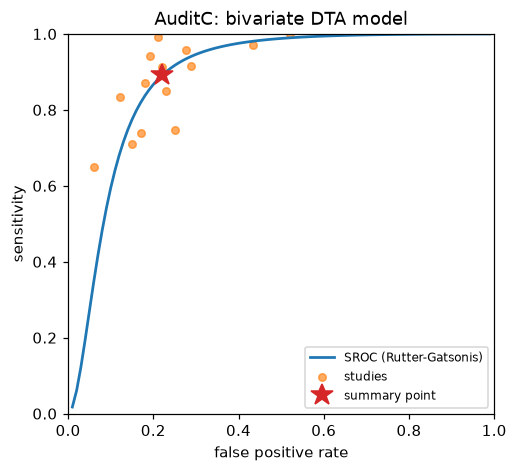

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot(curve.fpr, curve.tpr, lw=1.8, color="C0",
        label="SROC (Rutter-Gatsonis)")
ax.scatter(dta.fpr, dta.sens, s=24, alpha=0.65, color="C1", label="studies")
ax.plot(fit.summary_fpr, fit.summary_sens, "*", ms=15, color="C3",
        label="summary point")
ax.set_xlabel("false positive rate")
ax.set_ylabel("sensitivity")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("AuditC: bivariate DTA model")
plt.tight_layout()

## Cluster-robust variance

Ordinary standard errors assume independent estimates. When several estimates
come from one study, or several studies from one centre, they are too small.
The sandwich estimator fixes that, and it works on a plain `rma` fit as well as
on `rma.mv` — a univariate fit is just the case where the marginal covariance
happens to be diagonal.

| Option | What it does |
|---|---|
| `adjust=True` | CR1 (default), the `n/(n-p)` factor |
| `adjust=False` | CR0, no small-sample factor |
| `adjust="Stata2"` | CR1.S2, `n/(n-1)` |
| `clubSandwich=True` | CR2/CR3 with Satterthwaite degrees of freedom |

> **中文**　常规标准误假设估计之间独立。同一研究给出多个估计、或多个研究来自同一中心时，标准误会偏小。sandwich 估计量解决这个问题，`rma` 和 `rma.mv` 都能用 —— 单变量只是边际协方差恰好为对角的情形。

| 参数 | 作用 |
|---|---|
| `adjust=True` | CR1（默认），乘 `n/(n-p)` |
| `adjust=False` | CR0，不做小样本校正 |
| `adjust="Stata2"` | CR1.S2，乘 `n/(n-1)` |
| `clubSandwich=True` | CR2/CR3 + Satterthwaite 自由度 |


In [7]:
# Nine estimates in five clusters, so the small-sample factor is far from 1.
yi = np.array([0.20, 0.40, 0.10, 0.50, 0.30, 0.25, 0.45, 0.15, 0.35])
vi = np.array([0.040, 0.050, 0.030, 0.060, 0.020, 0.050, 0.045, 0.035, 0.055])
cluster = ["A", "A", "B", "B", "C", "C", "D", "D", "E"]

pooled = ma.rma(yi, vi=vi, method="REML")
print(f"{'naive':10s} se {pooled.se[0]:.5f}")

for label, kwargs in [("CR1", {}),
                      ("CR0", {"adjust": False}),
                      ("CR1.S2", {"adjust": "Stata2"}),
                      ("CR2+Satt", {"clubSandwich": True, "vcov": "CR2"})]:
    out = ma.robust(pooled, cluster=cluster, **kwargs)
    print(f"{label:10s} se {out['se'][0]:.5f}   p {out['pval'][0]:.4g}   "
          f"df {np.round(out['dfs'], 3)}")

naive      se 0.06538
CR1        se 0.01293   p 2.723e-05   df 4.0
CR0        se 0.01157   p 1.748e-05   df 4.0
CR1.S2     se 0.01293   p 2.723e-05   df 4.0
CR2+Satt   se 0.01219   p 6.644e-05   df [3.462]


## Making it reproducible

Both analyses drop into a record, and the record re-runs itself. The DTA fit
needs `pass_data=True` because `reitsma()` takes the whole counts table rather
than a set of column names, which the automatic inference cannot see.

> **中文**　两种分析都能进记录，而记录能自我重跑。DTA 需要 `pass_data=True`，因为 `reitsma()` 收的是整张计数表而不是一组列名 —— 自动推断看不出这一点。


In [8]:
import tempfile
from pathlib import Path

from pimeta.record import load_record, save_record

out = Path(tempfile.mkdtemp(prefix="pimeta-dta-"))
path = out / "dta.json"

record = save_record(path, fit, data=AUDITC, mode="bundle",
                     function="reitsma", call={"method": "reml"},
                     pass_data=True)
print(record.summary())
print()

reopened = load_record(path)
print("verify fingerprint:", reopened.verify()["analysis"])
print("replay coefficients:", np.round(reopened.replay().mu, 10).tolist())

reitsma  (pimeta.record/1)
  created      2026-10-22T09:15:56+00:00
  pimeta       1.1.0
  rows         14  (mode=bundle)
  source fp    sha256:684e4f03b3d3ec734312e12d3df95896
  analysis fp  sha256:4a7f1136ca9a7d924e81541bbcda3481
  settings     level=0.95, method=reml

verify fingerprint: sha256:4a7f1136ca9a7d924e81541bbcda3481
replay coefficients: [2.0997423525, -1.263690926]


## Summary

| Question | Use |
|---|---|
| 2×2 counts to effect sizes | `ma.escalc_dta(...)` |
| bivariate summary point | `ma.reitsma(dta)` |
| HSROC parameters | `ma.hsroc(fit)` |
| summary ROC and AUC | `ma.sroc(fit)`, `ma.auc(fit)` |
| cluster-robust standard errors | `ma.robust(fit, cluster=...)` |
| a file that re-runs itself | `ma.record.save_record(...)` |

The numbers above match `mada` 0.5.12 and `metafor` 5.2.1 on R 4.6.1; the full
comparison is in `tests/test_dta.py` and `tests/test_rve.py`.

Back to [`01-quickstart.ipynb`](01-quickstart.ipynb) if you skipped the basics.

**中文**

| 想知道 | 用 |
|---|---|
| 2×2 计数 → 效应量 | `ma.escalc_dta(...)` |
| 双变量汇总点 | `ma.reitsma(dta)` |
| HSROC 参数 | `ma.hsroc(fit)` |
| 汇总 ROC 与 AUC | `ma.sroc(fit)`、`ma.auc(fit)` |
| 聚类稳健标准误 | `ma.robust(fit, cluster=...)` |
| 能自我重跑的文件 | `ma.record.save_record(...)` |

上面的数字与 R 4.6.1 上的 `mada` 0.5.12、`metafor` 5.2.1 一致；完整对拍见 `tests/test_dta.py` 与 `tests/test_rve.py`。

基础内容没看的话，回到 [`01-quickstart.ipynb`](01-quickstart.ipynb)。
